In [14]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cmc


plt.style.use("../plotstyling.mplstyle")

In [15]:
aws_file = "/scratch/may/aws/L2_arctic/2026/01/l2_arctic_20260105003352_20260105021355_v3.nc"
#l2_arctic_20260105035109_20260105052857_v3_earthcare_ECA_EXBC_ACM_CAP_2B_20260105T050508Z_20260112T083627Z_09122C_fwp_v3.png

remap_distance units: m | range: 15.5085125 to 26773.248


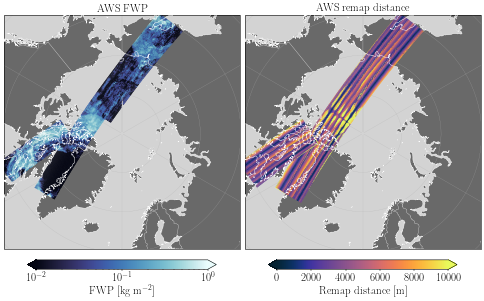

In [19]:
with xr.open_dataset(aws_file) as ds:
    remap_units = ds["remap_distance"].attrs.get("units", "?")
    print("remap_distance units:", remap_units,
          "| range:", np.nanmin(ds["remap_distance"].values), "to", np.nanmax(ds["remap_distance"].values))

# each panel: AWS file, variable, title, colour map, colour norm, colour bar label
panels = [
    (aws_file, "fwp_mean", "AWS FWP", cmc.cm.ice,
     LogNorm(vmin=1e-2, vmax=1e0), r"FWP [kg m$^{-2}$]"),
    (aws_file, "remap_distance", "AWS remap distance", cmc.cm.thermal,
     Normalize(vmin=0, vmax=10000), f"Remap distance [m]"),
]
lat_min = 60.0         # southern edge of the maps
marker_size = 1.0

geo = ccrs.PlateCarree()
fig, axes = plt.subplots(1, 2, figsize=(12, 9),
                         subplot_kw={"projection": ccrs.NorthPolarStereo()},
                         layout="constrained")

for ax, (path, var, title, cmap, norm, cbar_label) in zip(axes, panels):
    with xr.open_dataset(path) as ds:
        lat = ds["latitude"].values
        lon = ds["longitude"].values
        values = ds[var].values

    ax.set_extent([-180, 180, lat_min, 90], crs=geo)
    ax.add_feature(cfeature.OCEAN, facecolor="lightgrey", zorder=0)
    ax.add_feature(cfeature.LAND, facecolor="dimgrey", zorder=0)
    ax.add_feature(cfeature.BORDERS, edgecolor="white", linewidth=0.5, zorder=1)
    ax.coastlines(color="white", linewidth=0.8, zorder=10)
    ax.gridlines(draw_labels=False, linewidth=0.3)

    sc = ax.scatter(lon, lat, c=values, s=marker_size, ec="none",
                    norm=norm, cmap=cmap, transform=geo, zorder=2)
    ax.set_title(title)
    fig.colorbar(sc, ax=ax, orientation="horizontal", extend="both",
                 shrink=0.8, pad=0.03, label=cbar_label)

plt.savefig(f"../figures/remap_distance_example.png",
            facecolor="white", bbox_inches="tight", dpi=200)